# Preparación de las series para su análisis (CAT – MRK – MSFT)
**Dataset de entrada:** `dowjones_diario_2016_2025.csv` · **Ruta:** `Datos/Transformados/dowjones_diario_2016_2025.csv`

**Objetivo:** dejar las series de la cartera listas para el análisis: misma frecuencia documentada, rentabilidades logarítmicas y test ADF (Dickey-Fuller aumentado) sobre precios y rentabilidades.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

from packages.bbva_graficos import configurar_graficos, guardar_mpl, fmt_es, BBVA, cerrar_grafico
configurar_graficos()

ruta = 'Datos/Transformados/dowjones_diario_2016_2025.csv'
cartera = ['CAT', 'MRK', 'MSFT']
colores = {'CAT': BBVA['principal'], 'MRK': BBVA['agua'], 'MSFT': BBVA['medio']}
fuente_texto = 'dowjones_diario_2016_2025.csv'
fuente = f'Fuente: {fuente_texto}'

## 1. Frecuencia temporal
**Decisión:** se mantiene la frecuencia **diaria de sesiones bursátiles**, sin remuestrear.

**Justificación:**
- Los datos ya son diarios (un cierre por ticker y sesión), así que no hace falta transformarlos.
- Agregar a semanas o meses perdería información y dejaría muy pocas observaciones para los tests y para estimar σ y ρ.
- El Montecarlo posterior usa pasos diarios, y la anualización asume 252 sesiones al año.
- Se usa el cierre (`close`) de cada sesión.

Comprobamos que las tres series cumplen esto y que comparten exactamente las mismas fechas.

In [2]:
datos = pd.read_csv(ruta, parse_dates=['date'])
datos = datos[datos['symbol'].isin(cartera)]
precios = datos.pivot(index='date', columns='symbol', values='close')[cartera]

print('Filas por ticker y día (máx):', datos.groupby(['symbol', 'date']).size().max())
print('Valores nulos:', int(precios.isna().sum().sum()))
print('Sesiones por ticker:', precios.count().to_dict())
print('Rango:', precios.index.min().date(), 'a', precios.index.max().date())
print('Días de la semana presentes (0=lunes, 4=viernes):', sorted(precios.index.dayofweek.unique()))
print('Salto máximo entre sesiones (días naturales):', precios.index.to_series().diff().dt.days.max())
print('Sesiones por año:', precios.groupby(precios.index.year).size().unique())

Filas por ticker y día (máx): 1
Valores nulos: 0
Sesiones por ticker: {'CAT': 2514, 'MRK': 2514, 'MSFT': 2514}
Rango: 2016-01-04 a 2025-12-31
Días de la semana presentes (0=lunes, 4=viernes): [0, 1, 2, 3, 4]
Salto máximo entre sesiones (días naturales): 4.0
Sesiones por año: [252 251 253 250]


**Frecuencia documentada:** las tres series son **diarias (días hábiles de bolsa)**, con las mismas fechas y sin huecos ni duplicados. No se rellenan ni se eliminan datos.

## 2. Rentabilidades logarítmicas
$r_t = \ln(P_t / P_{t-1})$

**Justificación:**
- Son aditivas en el tiempo: la suma de 252 rentabilidades diarias es la rentabilidad anual. Por eso anualizamos con $252\cdot\text{media}$ y $\sqrt{252}\cdot\text{desviación}$.
- Son las que supone el modelo de movimiento browniano geométrico del Montecarlo, así que μ y σ se estiman con la misma magnitud con la que se simula.
- Estabilizan la escala: un movimiento de 1 \$ pesa distinto con un precio de 25 \$ que con uno de 500 \$, mientras que el porcentaje es comparable a lo largo del tiempo.

Se pierde la primera sesión, que no tiene día anterior.

In [3]:
retornos = np.log(precios / precios.shift(1)).dropna()
retornos.to_csv('outputs/retornos_logaritmicos_cartera.csv')

print('Sesiones de precios:', len(precios), '| sesiones de retornos:', len(retornos))
retornos.describe().round(4)

Sesiones de precios: 2514 | sesiones de retornos: 2513


symbol,CAT,MRK,MSFT
count,2513.0000,2513.0000,2513.0000
mean,0.0008,0.0003,0.0009
std,0.0192,0.0143,0.0169
min,-0.1534,-0.1038,-0.1595
25%,-0.0086,-0.0066,-0.0068
50%,0.0007,0.0003,0.0010
75%,0.0110,0.0076,0.0095
max,0.1101,0.0990,0.1329


## 3. Test ADF (Dickey-Fuller aumentado)
**Hipótesis:** $H_0$: la serie tiene raíz unitaria (**no** es estacionaria). $H_1$: la serie es estacionaria.
Con **p-valor < 0,05** se rechaza $H_0$ y consideramos la serie estacionaria.

**Configuración:** regresión con constante (`regression='c'`) y número de retardos elegido automáticamente por el criterio AIC (`autolag='AIC'`). El test se aplica a precios y a rentabilidades logarítmicas.

**Por qué importa:** muchos métodos estadísticos (correlaciones, varianzas, modelos de series temporales) suponen series estacionarias. Un precio con tendencia no lo es, y la correlación entre precios con tendencia puede ser espuria.

In [4]:
filas = []
for ticker in cartera:
    for nombre, serie in [('Precio', precios[ticker]), ('Rentabilidad log.', retornos[ticker])]:
        estadistico, p_valor, retardos, n_obs, criticos, _ = adfuller(serie, regression='c', autolag='AIC')
        filas.append([ticker, nombre, estadistico, p_valor, retardos, n_obs, criticos['5%']])

adf = pd.DataFrame(filas, columns=['Activo', 'Serie', 'Estadístico ADF', 'p-valor', 'Retardos', 'Observaciones', 'Valor crítico 5 %'])
adf['¿Estacionaria (p < 0,05)?'] = np.where(adf['p-valor'] < 0.05, 'Sí', 'No')
adf.to_csv('outputs/adf_cartera.csv', index=False)
adf.style.format({'Estadístico ADF': '{:.2f}', 'p-valor': '{:.4g}', 'Valor crítico 5 %': '{:.2f}'}).hide(axis='index')

/tmp/ipykernel_20884/504568610.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  estadistico, p_valor, retardos, n_obs, criticos, _ = adfuller(serie, regression='c', autolag='AIC')
/tmp/ipykernel_20884/504568610.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  estadistico, p_valor, retardos, n_obs, criticos, _ = adfuller(serie, regression='c', autolag='AIC')
/tmp/ipy

Activo,Serie,Estadístico ADF,p-valor,Retardos,Observaciones,Valor crítico 5 %,"¿Estacionaria (p < 0,05)?"
CAT,Precio,1.78,0.9983,26,2487,-2.86,No
CAT,Rentabilidad log.,-14.53,5.397e-27,12,2500,-2.86,Sí
MRK,Precio,-1.56,0.5052,9,2504,-2.86,No
MRK,Rentabilidad log.,-15.32,4.088e-28,12,2500,-2.86,Sí
MSFT,Precio,-0.03,0.9562,9,2504,-2.86,No
MSFT,Rentabilidad log.,-17.24,6.125e-30,8,2504,-2.86,Sí


Guardado: Graficos/adf_precios_cartera.png


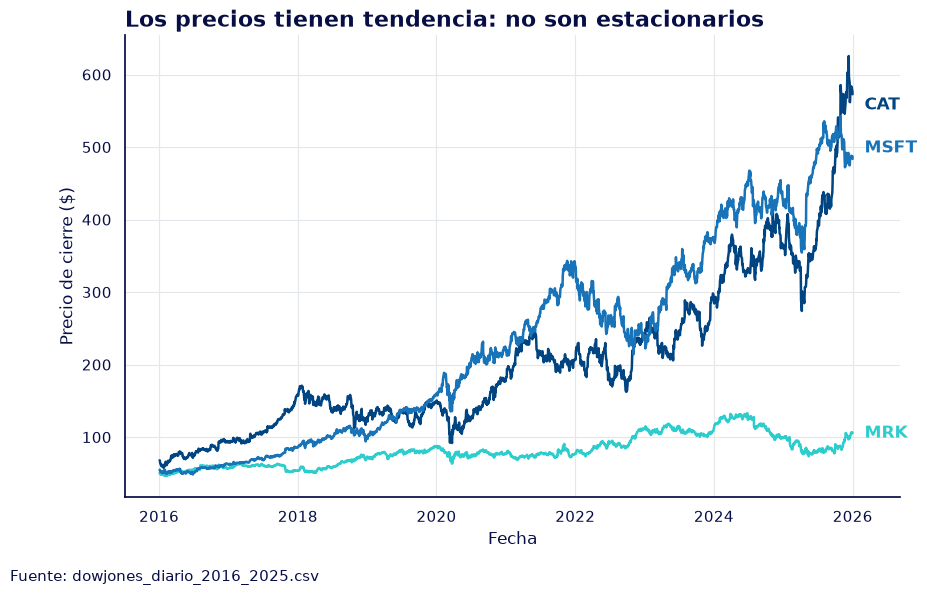

In [5]:
fig, ax = plt.subplots()
for ticker in cartera:
    ax.plot(precios[ticker], color=colores[ticker], linewidth=1.8)
ultima_fecha = precios.index[-1]
ax.text(ultima_fecha, precios['MSFT'].iloc[-1] + 15, '  MSFT', color=colores['MSFT'], fontweight='bold', fontsize=12, va='center')
ax.text(ultima_fecha, precios['CAT'].iloc[-1] - 15, '  CAT', color=colores['CAT'], fontweight='bold', fontsize=12, va='center')
ax.text(ultima_fecha, precios['MRK'].iloc[-1], '  MRK', color=colores['MRK'], fontweight='bold', fontsize=12, va='center')
ax.set_xlim(right=ultima_fecha + pd.Timedelta(days=250))
ax.set_title('Los precios tienen tendencia: no son estacionarios')
ax.set_xlabel('Fecha')
ax.set_ylabel('Precio de cierre ($)')
ax.yaxis.set_major_formatter(lambda v, _: fmt_es(v))
cerrar_grafico(fig, 'adf_precios_cartera', fuente=fuente_texto, ajustar_titulos=False)

Guardado: Graficos/adf_retornos_cartera.png


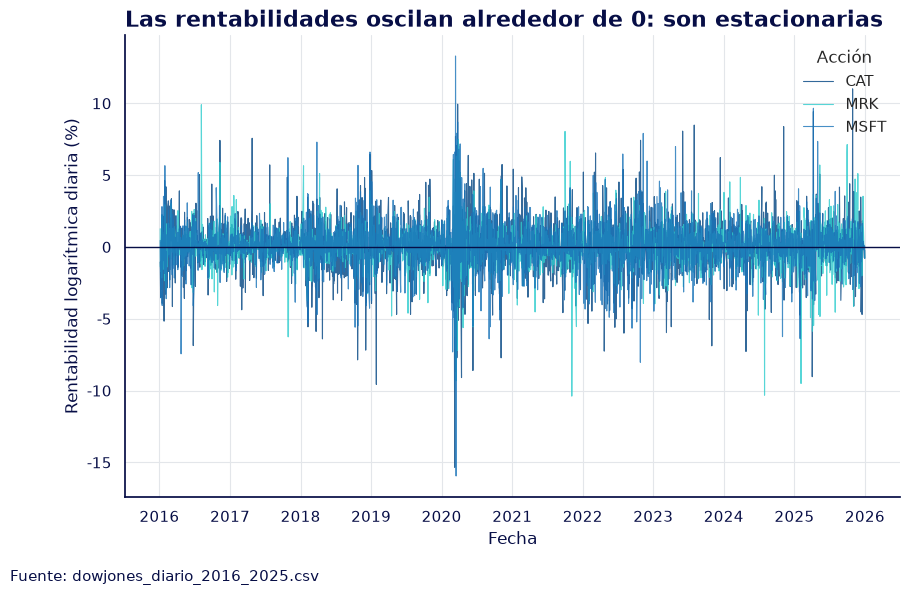

In [6]:
fig, ax = plt.subplots()
for ticker in cartera:
    ax.plot(retornos[ticker] * 100, color=colores[ticker], linewidth=0.8, alpha=0.8, label=ticker)
ax.axhline(0, color=BBVA['marino'], linewidth=1)
ax.set_title('Las rentabilidades oscilan alrededor de 0: son estacionarias')
ax.set_xlabel('Fecha')
ax.set_ylabel('Rentabilidad logarítmica diaria (%)')
ax.yaxis.set_major_formatter(lambda v, _: fmt_es(v))
ax.legend(title='Acción', loc='upper right')
cerrar_grafico(fig, 'adf_retornos_cartera', fuente=fuente_texto, ajustar_titulos=False)

## Conclusiones

**Frecuencia.** Las tres series (CAT, MRK, MSFT) son diarias, de días hábiles de bolsa, con 2.514 sesiones cada una entre el 04‑01‑2016 y el 31‑12‑2025, las mismas fechas y sin nulos ni duplicados (250–253 sesiones por año, coherente con las 252 usadas para anualizar).

**Rentabilidades.** Se calculan como $r_t=\ln(P_t/P_{t-1})$ (2.513 observaciones por activo) y se guardan en `outputs/retornos_logaritmicos_cartera.csv`.

**Test ADF** (constante y retardos por AIC; $H_0$: raíz unitaria):

| Activo | p‑valor precio | p‑valor rentabilidad |
|---|---|---|
| CAT | 0,998 | 5,4·10⁻²⁷ |
| MRK | 0,505 | 4,1·10⁻²⁸ |
| MSFT | 0,956 | 6,1·10⁻³⁰ |

- **Precios:** no se rechaza $H_0$ (p muy superior a 0,05) en ninguno de los tres: tienen raíz unitaria y no son estacionarios, algo coherente con su tendencia creciente.
- **Rentabilidades logarítmicas:** se rechaza $H_0$ con p prácticamente 0 en los tres: son estacionarias. El estadístico (entre −14,5 y −17,2) queda muy por debajo del valor crítico al 5 % (−2,86).

**Qué implica.** Trabajar con rentabilidades logarítmicas, y no con precios, es lo correcto para estimar μ, σ y las correlaciones que alimentan el Montecarlo.

**Limitación.** El ADF solo contrasta que no haya raíz unitaria. No garantiza varianza constante: las rentabilidades tienen épocas de más volatilidad (por ejemplo 2020), y la simulación con σ fija es una simplificación.